# Investigate alleles that increased abundance

Almost all variants with abundance changes that surpass assay variability are decreases in abundance. For the very few cases that increased abundance, we want to see if there is anything biologically interesting going on here.

In [1]:
import polars as pl

In [2]:
outputs_dir = "../3_outputs"

In [71]:
scores = pl.read_csv(f"{outputs_dir}/DUALIPA_median_zscore.csv")
incr_abun = scores.filter(pl.col("zscore_log2") > 3)
print(incr_abun.select(['symbol', 'aa_change', 'zscore_log2', 'clinvar_clnsig_clean', 'StarStatus']))

shape: (10, 5)
┌────────┬───────────┬─────────────┬──────────────────────┬────────────┐
│ symbol ┆ aa_change ┆ zscore_log2 ┆ clinvar_clnsig_clean ┆ StarStatus │
│ ---    ┆ ---       ┆ ---         ┆ ---                  ┆ ---        │
│ str    ┆ str       ┆ f64         ┆ str                  ┆ f64        │
╞════════╪═══════════╪═════════════╪══════════════════════╪════════════╡
│ KLHL3  ┆ Ala77Glu  ┆ 4.132357    ┆ 1_Pathogenic         ┆ null       │
│ BAG3   ┆ Leu462Pro ┆ 4.608951    ┆ 1_Pathogenic         ┆ 1.0        │
│ KLHL3  ┆ Glu85Ala  ┆ 4.24207     ┆ 1_Pathogenic         ┆ null       │
│ TPM1   ┆ Ala22Thr  ┆ 3.680749    ┆ 3_Conflicting        ┆ 1.0        │
│ HBD    ┆ Glu27Asp  ┆ 4.693279    ┆ 5_Others             ┆ null       │
│ TPM1   ┆ Glu23Gln  ┆ 3.102999    ┆ 4_VUS                ┆ 1.0        │
│ KLHL3  ┆ Cys164Phe ┆ 4.837172    ┆ 1_Pathogenic         ┆ null       │
│ TPM1   ┆ Lys15Asn  ┆ 4.564075    ┆ 3_Conflicting        ┆ 1.0        │
│ MID1   ┆ Pro151Leu ┆ 3.581701    ┆

/Users/jewald/miniforge3/envs/dual-ipa/lib/python3.11/site-packages/plotnine/layer.py:284: PlotnineWarning: stat_boxplot : Removed 74 rows containing non-finite values.
/Users/jewald/miniforge3/envs/dual-ipa/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_jitter : Removed 74 rows containing missing values.


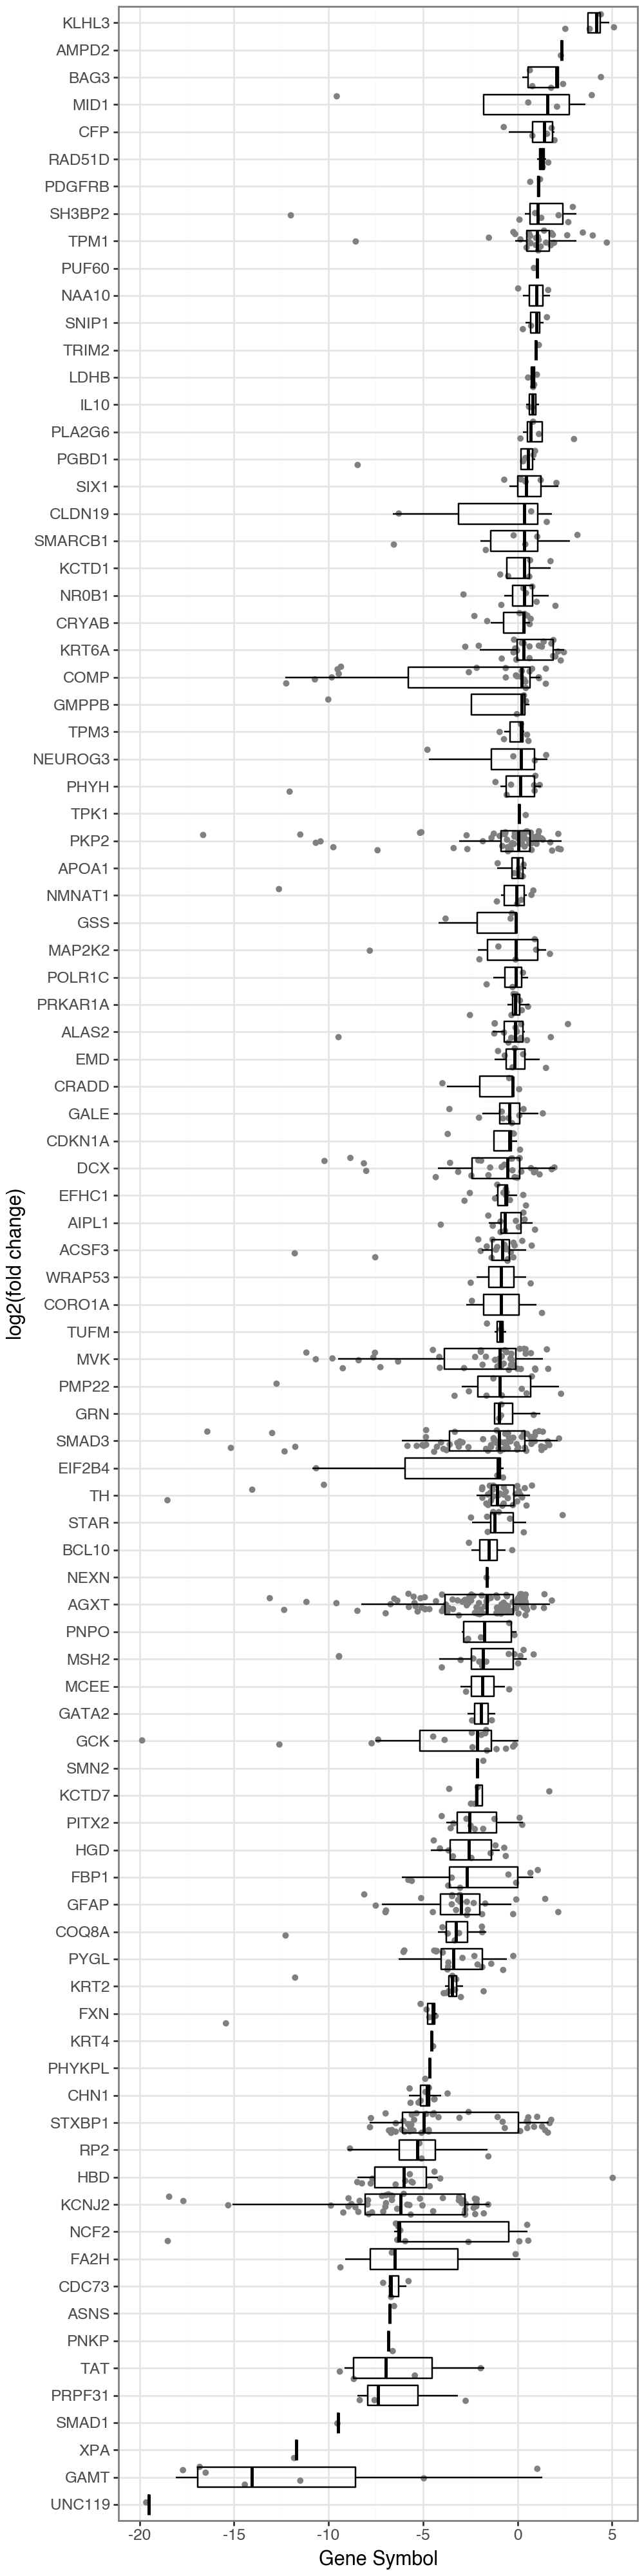

In [ ]:
from plotnine import ggplot, aes, geom_jitter, theme_bw, xlab, ylab, theme, geom_boxplot, coord_flip
import plotnine as pn
from matplotlib import pyplot as plt
import pandas as pd

pn.options.figure_size = (5,20)

symbol_medians = scores.filter(~pl.col("zscore_log2").is_null()).group_by("symbol").agg(
    pl.col("zscore_log2").median().alias("median_log2")
).sort("median_log2")

symbol_order = symbol_medians.select('symbol').to_series().to_list()

scores_plot = scores.join(symbol_medians, on="symbol").to_pandas()

scores_plot['symbol'] = pd.Categorical(scores_plot['symbol'], categories=symbol_order, ordered=True)

plot = (
    ggplot(scores_plot, aes(y='zscore_log2', x='symbol')) +
    geom_jitter(size=1, color='grey') +
    geom_boxplot(fill=None, color="black", outlier_shape="") +
    coord_flip() +
    theme_bw() +
    xlab('log2(fold change)') +
    ylab('Gene Symbol') +
    theme(legend_position='none')
)

plot.show()